### ==========================================

# IRIS DATASET CLASSIFICATION PROJECT

# Logistic Regression vs Decision Tree

### ==========================================

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# 1. Load Dataset
iris = load_iris()
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
y = iris.target
df = X.copy()
df["Species"] = [iris.target_names[i] for i in y]
print("First Five Rows:")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDataset Information:")
print(df.info())

First Five Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset Shape: (150, 5)

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    floa

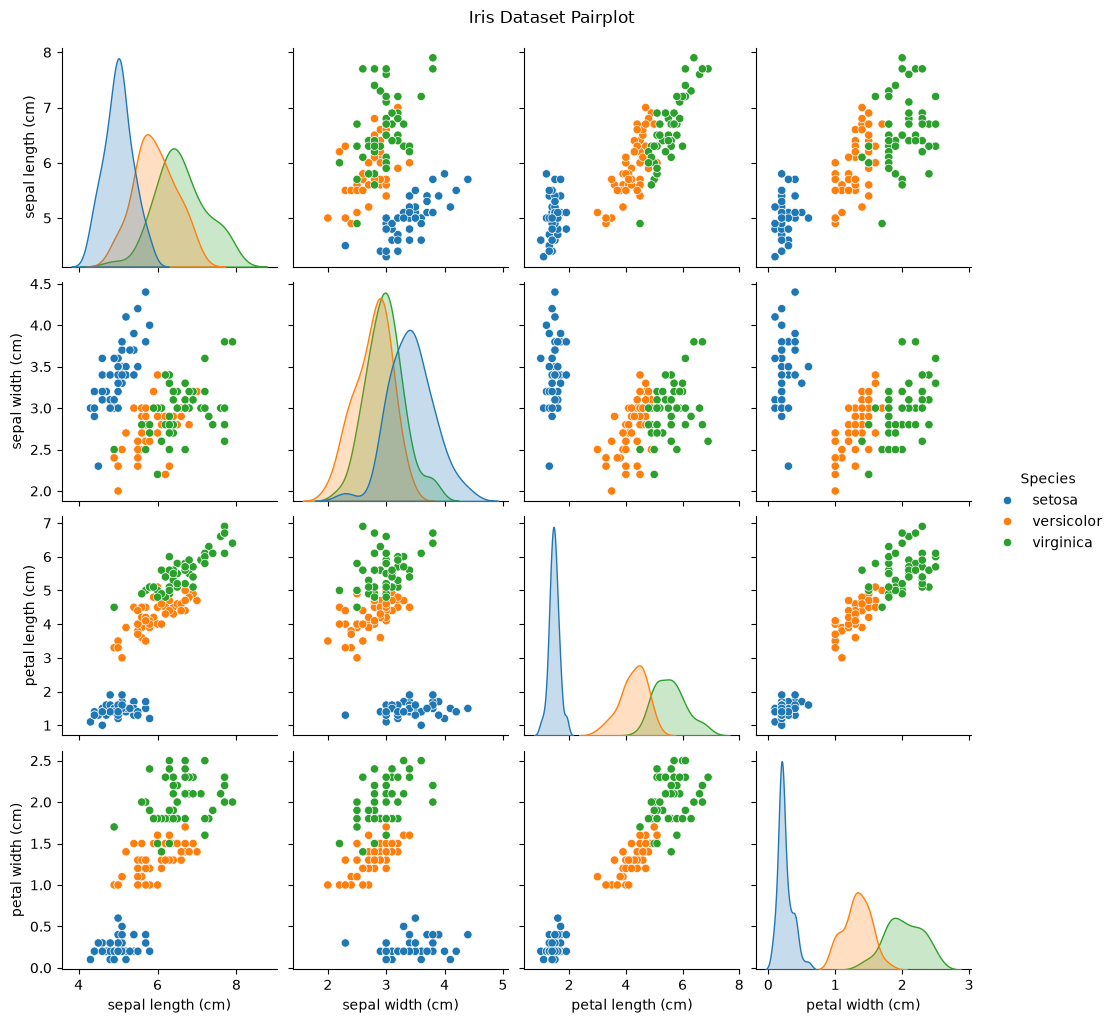

In [ ]:
# 2. Exploratory Data Analysis
sns.pairplot(df, hue="Species")
plt.suptitle("Iris Dataset Pairplot", y=1.02)
plt.show()

In [ ]:
# 3. Split Dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 120
Testing Samples: 30


In [ ]:
# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:

# 5. Train Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}
results = []
predictions = {}
for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names,
            zero_division=0
        )
    )



Logistic Regression

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
# 6. Compare Model Performance
results_df = pd.DataFrame(results)
print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))



MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9333     0.9333  0.9333    0.9333
      Decision Tree    0.9333     0.9333  0.9333    0.9333


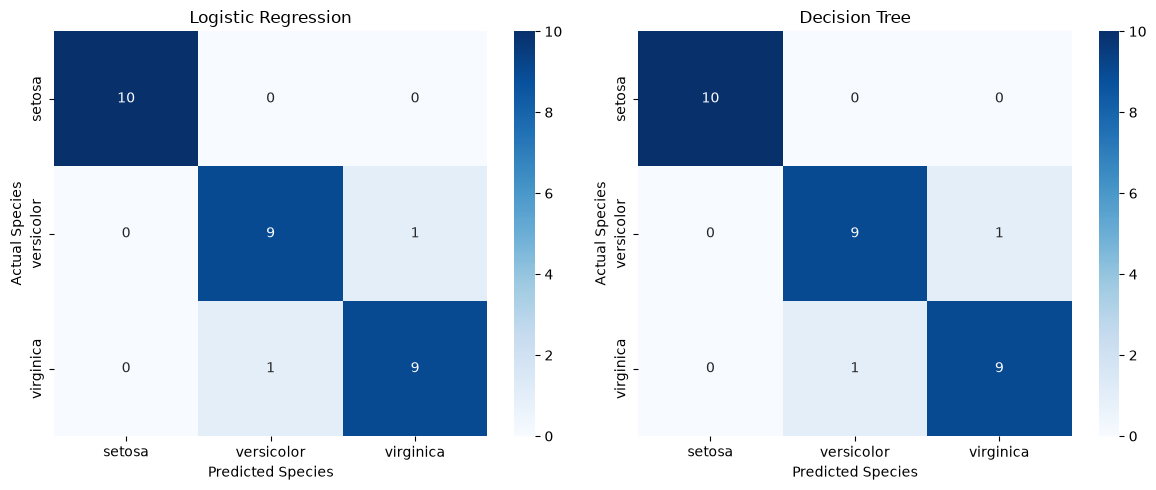

In [ ]:
# 7. Plot Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


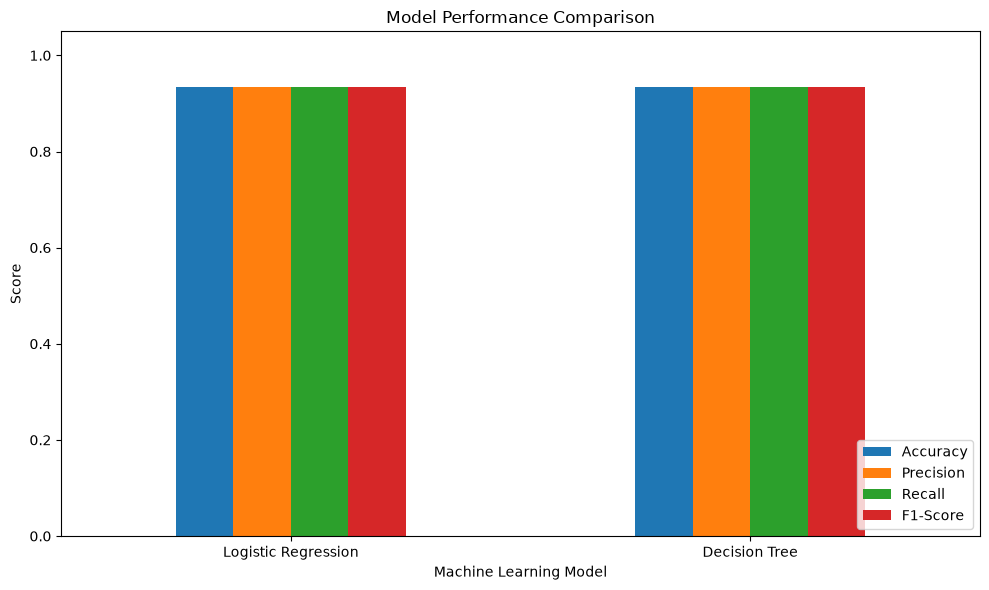

In [ ]:
# 8. Compare Metrics Using a Bar Chart
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


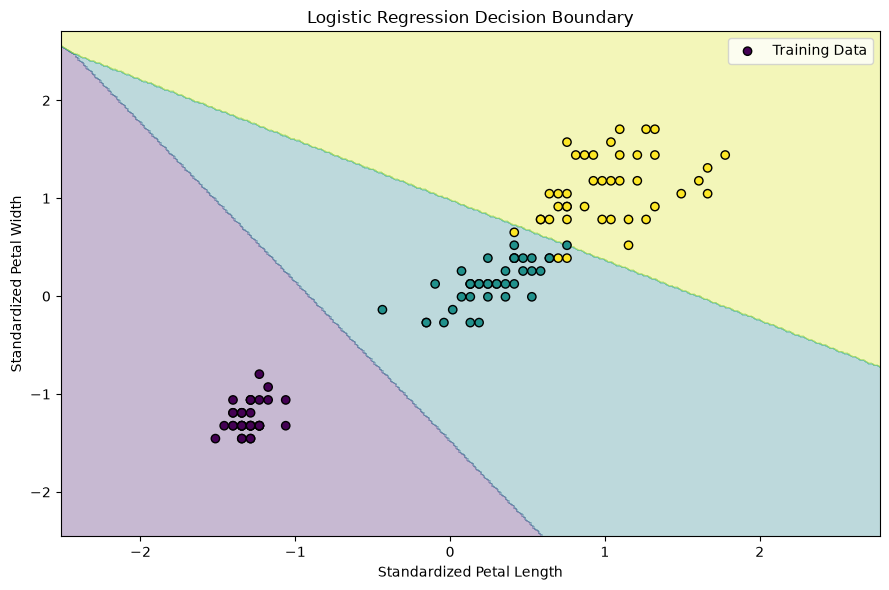


Project completed successfully!


In [ ]:
# 9. Decision Boundary Visualization
# Use two features for a 2D visualization.

X_2d = X.iloc[:, [2, 3]].to_numpy()

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler_2d = StandardScaler()

X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train a separate Logistic Regression model
boundary_model = LogisticRegression(max_iter=1000)

boundary_model.fit(X_train_2d_scaled, y_train_2d)

# Create a mesh grid
x_min = X_train_2d_scaled[:, 0].min() - 1
x_max = X_train_2d_scaled[:, 0].max() + 1

y_min = X_train_2d_scaled[:, 1].min() - 1
y_max = X_train_2d_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = boundary_model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap="viridis"
)

plt.scatter(
    X_train_2d_scaled[:, 0],
    X_train_2d_scaled[:, 1],
    c=y_train_2d,
    edgecolors="black",
    cmap="viridis",
    label="Training Data"
)

plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Standardized Petal Length")
plt.ylabel("Standardized Petal Width")
plt.legend()
plt.tight_layout()
plt.show()

print("\nProject completed successfully!")
